# EDA — Performances en Powerlifting
Objectif : prédire `TotalKg` (régression).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 100

train = pd.read_csv('train.csv')
test  = pd.read_csv('test.csv')
print('Train:', train.shape, '| Test:', test.shape)

Train: (105000, 18) | Test: (45000, 17)


## 1. Vue d'ensemble

In [2]:
train.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,105000.0,NaN,NaN,NaN,74972.531362,43332.026782,1.0,37474.75,74906.5,112544.25,149999.0
Age,105000.0,NaN,NaN,NaN,28.537771,12.056412,0.5,19.5,25.0,34.0,92.5
BodyweightKg,105000.0,NaN,NaN,NaN,83.423773,21.984334,19.1,67.09,81.4,97.1,241.8
MeetYear,105000.0,NaN,NaN,NaN,2017.667495,8.013321,1966.0,2015.0,2019.0,2023.0,2026.0
Sex,105000,3,M,72454,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Equipment,105000,5,Raw,65234,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AgeClass,105000,19,24-34,33827,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BirthYearClass,105000,8,24-39,41158,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WeightClassKg,105000,146,90,8193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tested,105000,2,Yes,80018,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# Valeurs manquantes
missing = train.isnull().sum()
print('Valeurs manquantes:\n', missing[missing > 0] if missing.any() else 'Aucune')

Valeurs manquantes:
 Aucune


## 2. Distribution de la cible (TotalKg)

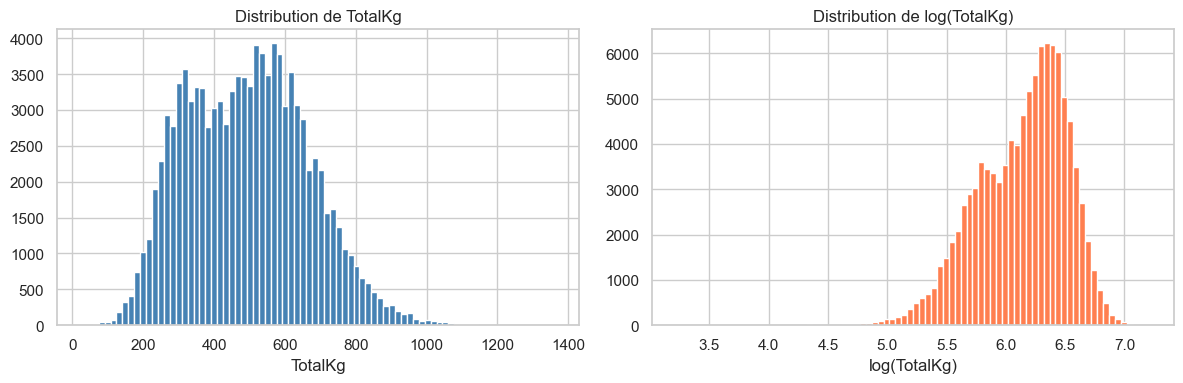

count    105000.000000
mean        493.011946
std         171.397819
min          24.000000
25%         352.500000
50%         492.500000
75%         612.500000
max        1363.050000
Name: TotalKg, dtype: float64


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

train['TotalKg'].hist(bins=80, ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('Distribution de TotalKg')
axes[0].set_xlabel('TotalKg')

np.log1p(train['TotalKg']).hist(bins=80, ax=axes[1], color='coral', edgecolor='white')
axes[1].set_title('Distribution de log(TotalKg)')
axes[1].set_xlabel('log(TotalKg)')

plt.tight_layout()
plt.show()

print(train['TotalKg'].describe())

## 3. Variables numériques vs TotalKg

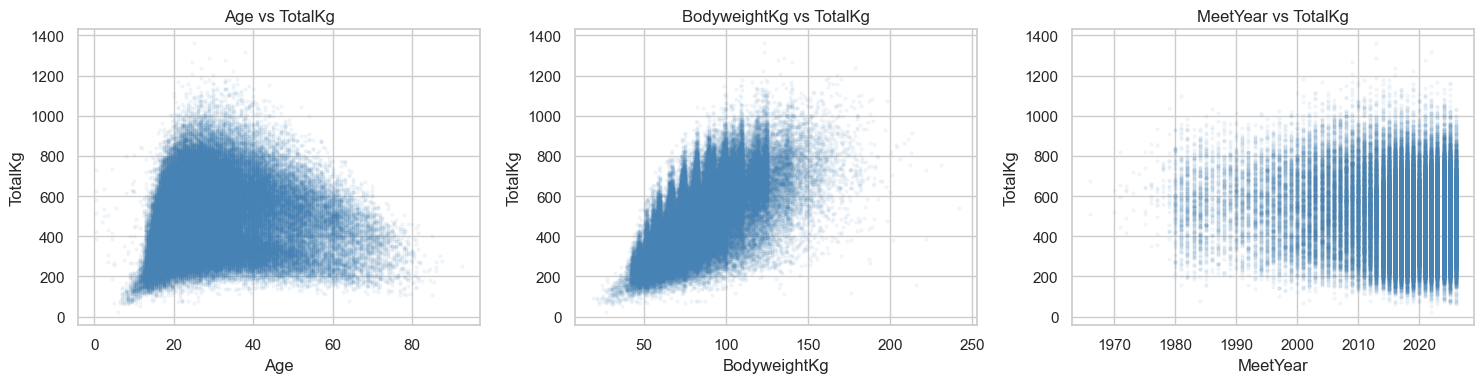

In [5]:
num_cols = ['Age', 'BodyweightKg', 'MeetYear']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    ax.scatter(train[col], train['TotalKg'], alpha=0.05, s=5, color='steelblue')
    ax.set_xlabel(col)
    ax.set_ylabel('TotalKg')
    ax.set_title(f'{col} vs TotalKg')
plt.tight_layout()
plt.show()

In [6]:
# Corrélations
corr = train[num_cols + ['TotalKg']].corr()['TotalKg'].drop('TotalKg').sort_values(key=abs, ascending=False)
print('Corrélations avec TotalKg:\n', corr)

Corrélations avec TotalKg:
 BodyweightKg    0.659013
MeetYear       -0.124203
Age             0.035418
Name: TotalKg, dtype: float64


## 4. Variables catégorielles vs TotalKg

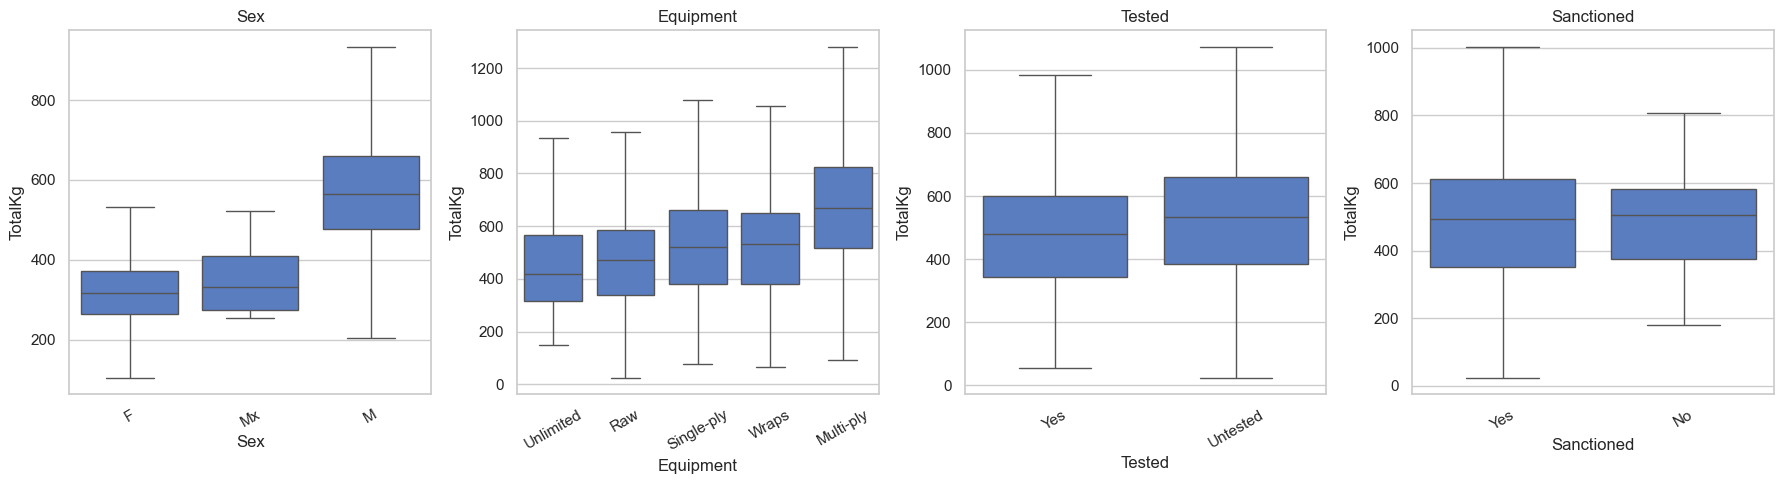

In [7]:
cat_cols = ['Sex', 'Equipment', 'Tested', 'Sanctioned']

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, col in zip(axes, cat_cols):
    order = train.groupby(col)['TotalKg'].median().sort_values().index
    sns.boxplot(data=train, x=col, y='TotalKg', order=order, ax=ax, showfliers=False)
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

## 5. Interaction Sex × Equipment

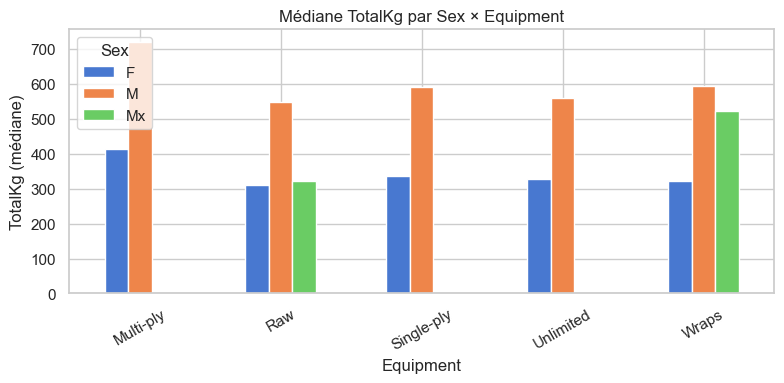

Equipment  Multi-ply    Raw  Single-ply  Unlimited  Wraps
Sex                                                      
F              413.8  310.0       335.0      326.6  322.5
M              720.0  547.5       590.0      560.2  595.0
Mx               NaN  321.2         NaN        NaN  522.5


In [8]:
pivot = train.groupby(['Sex', 'Equipment'])['TotalKg'].median().unstack()

fig, ax = plt.subplots(figsize=(8, 4))
pivot.T.plot(kind='bar', ax=ax)
ax.set_title('Médiane TotalKg par Sex × Equipment')
ax.set_xlabel('Equipment')
ax.set_ylabel('TotalKg (médiane)')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()
print(pivot.round(1))

## 6. Évolution temporelle (MeetYear)

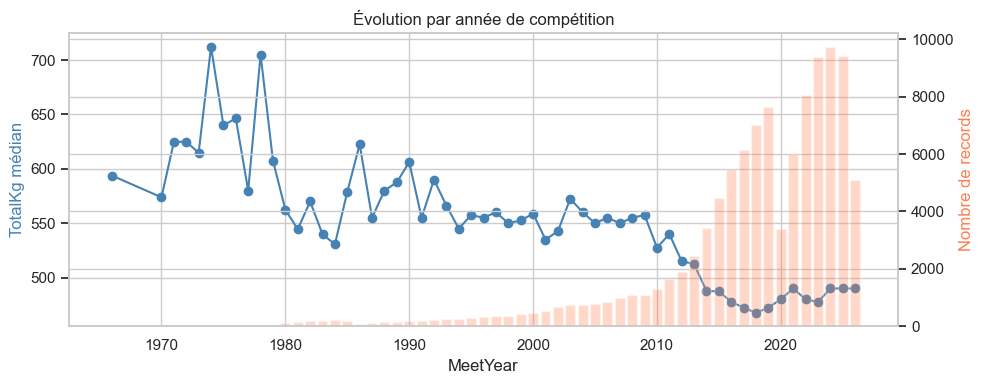

In [9]:
year_stats = train.groupby('MeetYear')['TotalKg'].agg(['median', 'count'])

fig, ax1 = plt.subplots(figsize=(10, 4))
ax2 = ax1.twinx()
ax1.plot(year_stats.index, year_stats['median'], marker='o', color='steelblue', label='Médiane TotalKg')
ax2.bar(year_stats.index, year_stats['count'], alpha=0.3, color='coral', label='Nb athlètes')
ax1.set_xlabel('MeetYear')
ax1.set_ylabel('TotalKg médian', color='steelblue')
ax2.set_ylabel('Nombre de records', color='coral')
ax1.set_title('Évolution par année de compétition')
plt.tight_layout()
plt.show()

## 7. Matrice de corrélation (numériques)

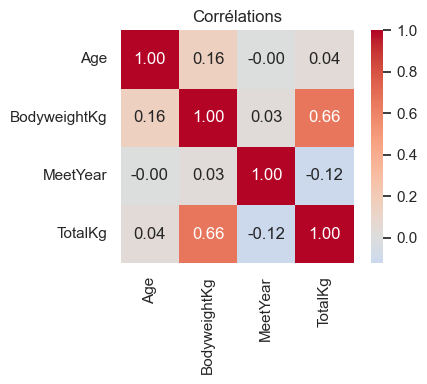

In [10]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(
    train[num_cols + ['TotalKg']].corr(),
    annot=True, fmt='.2f', cmap='coolwarm', center=0,
    square=True, ax=ax
)
ax.set_title('Corrélations')
plt.tight_layout()
plt.show()

## 8. Résumé des observations

| Observation | Détail |
|---|---|
| **Pas de valeurs manquantes** | Données propres |
| **BodyweightKg** | Corrélation la plus forte avec TotalKg |
| **Sex** | Hommes ~200 kg au-dessus des femmes (médiane) |
| **Equipment** | Multi-ply > Single-ply > Wraps > Raw |
| **Tested** | Athlètes non-testés ont un TotalKg légèrement supérieur |
| **MeetYear** | Croissance du nombre de compétitions récentes |
| **Outliers** | Quelques valeurs très basses (< 100 kg) à surveiller |